## ⚙️ **Libraries Import**

In [10]:
# Set seed for reproducibility
SEED = 64

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np
import pandas as pd

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision.transforms import v2 as transforms
from torch.utils.data import TensorDataset, DataLoader
!pip install torchview
from torchview import draw_graph

# Configurazione di TensorBoard e directory
logs_dir = "tensorboard"
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import requests
from io import BytesIO
import cv2
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard
PyTorch version: 2.6.0+cu124
Device: cuda


## ⏳ **Data Loading**

In [11]:
# Path Setup based on your description
DATASET_ROOT = os.path.join('/kaggle/input', 'ann-c2/Dataset')
TRAIN_DIR = os.path.join(DATASET_ROOT, 'train_data') # Contains BOTH images and masks
TEST_DIR = os.path.join(DATASET_ROOT, 'test_data')
LABEL_FILE = os.path.join(DATASET_ROOT, 'train_labels.csv')

print(f"Training Data Directory: {TRAIN_DIR}")
print(f"Labels File: {LABEL_FILE}")

Training Data Directory: /kaggle/input/ann-c2/Dataset/train_data
Labels File: /kaggle/input/ann-c2/Dataset/train_labels.csv


In [ ]:
def prepare_data_splits():
    """
    Reads the CSV and creates 80/20 Train/Val split lists.
    Reads the Test Directory for Inference lists.
    """
    # Load Labels CSV
    df = pd.read_csv(LABEL_FILE)

    # Map text labels to integers if needed
    if 'label_idx' not in df.columns:
        label_map = {'Luminal A': 0, 'Luminal B': 1, 'HER2(+)': 2, 'Triple negative': 3}
        df['label_idx'] = df['label'].map(label_map)

    # Split into Train (80%) and Validation (20%)
    train_df, val_df = train_test_split(
        df,
        test_size=0.2,
        random_state=SEED,
        stratify=df['label_idx']
    )

    print(f"Training Samples: {len(train_df)}")
    print(f"Validation Samples: {len(val_df)}")

    # Prepare Test Data (Inference)
    test_files = [f for f in os.listdir(TEST_DIR) if f.startswith("img_") and f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    print(f"Inference Test Samples: {len(test_files)}")

    return train_df, val_df, test_files

# Execute the split
train_df, val_df, test_files = prepare_data_splits()

Training Samples: 464
Validation Samples: 117
Inference Test Samples: 477


In [13]:
# Image and Batch Size config
IMG_SIZE = 244
BATCH_SIZE = 8

In [ ]:
input_shape = (3, IMG_SIZE, IMG_SIZE)
num_classes = 4

print("Input Shape:", input_shape)
print("Number of Classes:", num_classes)

Input Shape: (3, 244, 244)
Number of Classes: 4


In [ ]:
class GrumpyDoctogresDataset(torch.utils.data.Dataset):
    def __init__(self, samples, data_dir, labels=None, transform=None, patch_size=256, crops_per_image=1):
        """
        Args:
            crops_per_image (int): Number of different crops to generate from each image per epoch.
                                   Default is 1 (standard behavior).
        """
        self.samples = samples
        self.labels = labels
        self.data_dir = data_dir
        self.transform = transform
        self.patch_size = patch_size
        self.crops_per_image = crops_per_image

    def __len__(self):
        # Virtually increase dataset size by the multiplier
        return len(self.samples) * self.crops_per_image

    def __getitem__(self, idx):
        # Map the virtual index back to the actual sample index
        original_idx = idx % len(self.samples)
        
        img_filename = self.samples[original_idx]
        img_path = os.path.join(self.data_dir, img_filename)
        
        # Load Image
        image = Image.open(img_path).convert('RGB')
        w, h = image.size
        
        # Load Mask
        mask_filename = img_filename.replace('img_', 'mask_').rsplit('.', 1)[0] + '.png'
        mask_path = os.path.join(self.data_dir, mask_filename)
        
        # POSITIVE-PIXEL SAMPLING
        crop_center_y, crop_center_x = h // 2, w // 2

        if os.path.exists(mask_path):
            mask = Image.open(mask_path).convert('L')
            mask_np = np.array(mask)

            # Get coordinates of positive pixels
            y_indices, x_indices = np.where(mask_np > 0)
            
            if len(y_indices) > 0:
                # Pick ONE random tissue pixel to be the center
                random_idx = np.random.randint(len(y_indices))
                crop_center_y = y_indices[random_idx]
                crop_center_x = x_indices[random_idx]

        # Calculate Crop Box
        half_size = self.patch_size // 2
        
        top = max(0, crop_center_y - half_size)
        left = max(0, crop_center_x - half_size)
        
        # Adjust if box goes off-edge
        if top + self.patch_size > h: top = max(0, h - self.patch_size)
        if left + self.patch_size > w: left = max(0, w - self.patch_size)
        
        # Perform the Crop
        image = image.crop((left, top, left + self.patch_size, top + self.patch_size))
        
        # Fallback resize if image was smaller than patch_size
        if image.size != (self.patch_size, self.patch_size):
             image = image.resize((self.patch_size, self.patch_size), Image.BILINEAR)

        # Apply Transforms (RandAugment, Normalization)
        if self.transform:
            image = self.transform(image)

        if self.labels is not None:
            return image, self.labels[original_idx] # Use original_idx for labels too
        return image, img_filename

In [ ]:
train_transform = transforms.Compose([
    transforms.RandAugment(num_ops=2, magnitude=9),
    
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [17]:
def make_loader(ds, batch_size, shuffle, drop_last):
    """Create a PyTorch DataLoader with optimized settings."""
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,
    )

##  🧠 **Training Functions**

In [18]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device, l1_lambda=0, l2_lambda=0):
    """
    Perform one complete training epoch through the entire training dataset.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): Lambda for L1 regularization
        l2_lambda (float): Lambda for L2 regularization

    Returns:
        tuple: (average_loss, f1 score) - Training loss and f1 score for this epoch
    """
    model.train()  # Set model to training mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Iterate through training batches
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        # Move data to device (GPU/CPU)
        inputs, targets = inputs.to(device), targets.to(device)

        # Clear gradients from previous step
        optimizer.zero_grad(set_to_none=True)

        # Forward pass with mixed precision (if CUDA available)
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs)
            loss = criterion(logits, targets)

            # Add L1 and L2 regularization
            l1_norm = sum(p.abs().sum() for p in model.parameters())
            l2_norm = sum(p.pow(2).sum() for p in model.parameters())
            loss = loss + l1_lambda * l1_norm + l2_lambda * l2_norm


        # Backward pass with gradient scaling
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        # Accumulate metrics
        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_f1


def validate_one_epoch(model, val_loader, criterion, device):
    """
    Perform one complete validation epoch through the entire validation dataset.

    Args:
        model (nn.Module): The neural network model to evaluate (must be in eval mode)
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        criterion (nn.Module): Loss function used to calculate validation loss
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)

    Returns:
        tuple: (average_loss, accuracy) - Validation loss and accuracy for this epoch

    Note:
        This function automatically sets the model to evaluation mode and disables
        gradient computation for efficiency during validation.
    """
    model.eval()  # Set model to evaluation mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Disable gradient computation for validation
    with torch.no_grad():
        for inputs, targets in val_loader:
            # Move data to device
            inputs, targets = inputs.to(device), targets.to(device)

            # Forward pass with mixed precision (if CUDA available)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs)
                loss = criterion(logits, targets)

            # Accumulate metrics
            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_accuracy = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_accuracy


def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, writer=None, verbose=10, experiment_name=""):
    """
    Train the neural network model on the training data and validate on the validation data.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        epochs (int): Number of training epochs
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): L1 regularization coefficient (default: 0)
        l2_lambda (float): L2 regularization coefficient (default: 0)
        patience (int): Number of epochs to wait for improvement before early stopping (default: 0)
        evaluation_metric (str): Metric to monitor for early stopping (default: "val_f1")
        mode (str): 'max' for maximizing the metric, 'min' for minimizing (default: 'max')
        restore_best_weights (bool): Whether to restore model weights from best epoch (default: True)
        writer (SummaryWriter, optional): TensorBoard SummaryWriter object for logging (default: None)
        verbose (int, optional): Frequency of printing training progress (default: 10)
        experiment_name (str, optional): Experiment name for saving models (default: "")

    Returns:
        tuple: (model, training_history) - Trained model and metrics history
    """

    # Initialize metrics tracking
    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': []
    }

    # Configure early stopping if patience is set
    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")

    # Main training loop: iterate through epochs
    for epoch in range(1, epochs + 1):

        # Forward pass through training data, compute gradients, update weights
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device, l1_lambda, l2_lambda
        )

        # Evaluate model on validation data without updating weights
        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        # Store metrics for plotting and analysis
        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)

        # Print progress every N epochs or on first epoch
        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, F1 Score={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1 Score={val_f1:.4f}")

        # Early stopping logic: monitor metric and save best model
        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    # Restore best model weights if early stopping was used
    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load("models/"+experiment_name+'_model.pt'))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    # Save final model if no early stopping
    if patience == 0:
        torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')

    # Close TensorBoard writer
    if writer is not None:
        writer.close()

    return model, training_history

##  🧮 **Network Parameters**



In [19]:
class_weights = compute_class_weight(
    class_weight='balanced', 
    classes=np.unique(train_df['label_idx']), 
    y=train_df['label_idx']
)

class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

In [20]:
# Training parameters
LEARNING_RATE = 1e-5

EPOCHS = 200
PATIENCE = 25

# Regularization
DROPOUT_RATE = 0.4
CROPS_PER_IMAGE = 5


# Set up loss function
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Print the defined parameters
print("Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Learning Rate:", LEARNING_RATE)
print("Dropout Rate:", DROPOUT_RATE)
print("Patience:", PATIENCE)

Epochs: 200
Batch Size: 8
Learning Rate: 1e-05
Dropout Rate: 0.4
Patience: 25


## 🛠️ **Transfer Learning**





In [ ]:
# Replace your current model class with this one
class ResNet50TransferLearning(nn.Module):
    def __init__(self, num_classes, dropout_rate=0.5, freeze_backbone=True):
        super().__init__()
        
        # Load ResNet50 with ImageNet weights
        weights = torchvision.models.ResNet50_Weights.IMAGENET1K_V2
        self.backbone = torchvision.models.resnet50(weights=weights)

        # Freeze backbone weights if requested
        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False

        # Replace the Head (ResNet uses 'fc', MobileNet uses 'classifier')
        in_features = self.backbone.fc.in_features
        
        self.backbone.fc = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        return self.backbone(x)

In [ ]:
# Create transfer learning model
tl_model = ResNet50TransferLearning(num_classes, DROPOUT_RATE, freeze_backbone=True).to(device)

# Display model summary
summary(tl_model, input_size=input_shape)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 189MB/s] 


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 122, 122]           9,408
       BatchNorm2d-2         [-1, 64, 122, 122]             128
              ReLU-3         [-1, 64, 122, 122]               0
         MaxPool2d-4           [-1, 64, 61, 61]               0
            Conv2d-5           [-1, 64, 61, 61]           4,096
       BatchNorm2d-6           [-1, 64, 61, 61]             128
              ReLU-7           [-1, 64, 61, 61]               0
            Conv2d-8           [-1, 64, 61, 61]          36,864
       BatchNorm2d-9           [-1, 64, 61, 61]             128
             ReLU-10           [-1, 64, 61, 61]               0
           Conv2d-11          [-1, 256, 61, 61]          16,384
      BatchNorm2d-12          [-1, 256, 61, 61]             512
           Conv2d-13          [-1, 256, 61, 61]          16,384
      BatchNorm2d-14          [-1, 256,

In [ ]:
# Training Dataset
# Generate 10 random crops per image per epoch
train_dataset = GrumpyDoctogresDataset(
    samples=train_df['sample_index'].tolist(),
    labels=train_df['label_idx'].tolist(),
    data_dir=TRAIN_DIR,
    transform=train_transform,
    crops_per_image=CROPS_PER_IMAGE
)

# Validation Dataset
# Keep validation deterministic/single crop (crops_per_image=1 by default)
val_dataset = GrumpyDoctogresDataset(
    samples=val_df['sample_index'].tolist(),
    labels=val_df['label_idx'].tolist(),
    data_dir=TRAIN_DIR,
    transform=val_transform
)

# Test (Inference) Dataset
test_dataset = GrumpyDoctogresDataset(
    samples=test_files,
    labels=None,
    data_dir=TEST_DIR,
    transform=val_transform
)

# Data Loaders
train_loader = make_loader(train_dataset, BATCH_SIZE, shuffle=True, drop_last=False)
val_loader = make_loader(val_dataset, BATCH_SIZE, shuffle=False, drop_last=False)
test_loader = make_loader(test_dataset, BATCH_SIZE, shuffle=False, drop_last=False)

print(f"Original Training Samples: {len(train_df)}")
print(f"Augmented Training Samples: {len(train_dataset)}")
print("\nDataLoaders created successfully.")

Original Training Samples: 464
Augmented Training Samples: 2320
\nDataLoaders created successfully.


In [24]:
# Setup training
experiment_name = "transfer_learning"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)

optimizer = torch.optim.Adam(
    tl_model.parameters(), 
    lr=LEARNING_RATE, 
    weight_decay=5e-4
)
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

In [25]:
%%time
# Train with transfer learning
tl_model, tl_history = fit(
    model=tl_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=1,
    experiment_name="transfer_learning",
    patience=PATIENCE
)

Training 200 epochs...
Epoch   1/200 | Train: Loss=1.3858, F1 Score=0.2329 | Val: Loss=1.3789, F1 Score=0.2427
Epoch   2/200 | Train: Loss=1.3799, F1 Score=0.3144 | Val: Loss=1.3737, F1 Score=0.3482
Epoch   3/200 | Train: Loss=1.3782, F1 Score=0.2944 | Val: Loss=1.3760, F1 Score=0.3687
Epoch   4/200 | Train: Loss=1.3720, F1 Score=0.3292 | Val: Loss=1.3740, F1 Score=0.3100
Epoch   5/200 | Train: Loss=1.3682, F1 Score=0.3508 | Val: Loss=1.3704, F1 Score=0.3624
Epoch   6/200 | Train: Loss=1.3636, F1 Score=0.3539 | Val: Loss=1.3571, F1 Score=0.4708
Epoch   7/200 | Train: Loss=1.3607, F1 Score=0.3459 | Val: Loss=1.3671, F1 Score=0.3547
Epoch   8/200 | Train: Loss=1.3595, F1 Score=0.3590 | Val: Loss=1.3626, F1 Score=0.3999
Epoch   9/200 | Train: Loss=1.3510, F1 Score=0.3862 | Val: Loss=1.3510, F1 Score=0.4058
Epoch  10/200 | Train: Loss=1.3467, F1 Score=0.3877 | Val: Loss=1.3579, F1 Score=0.3568
Epoch  11/200 | Train: Loss=1.3470, F1 Score=0.3604 | Val: Loss=1.3576, F1 Score=0.4174
Epoch  12

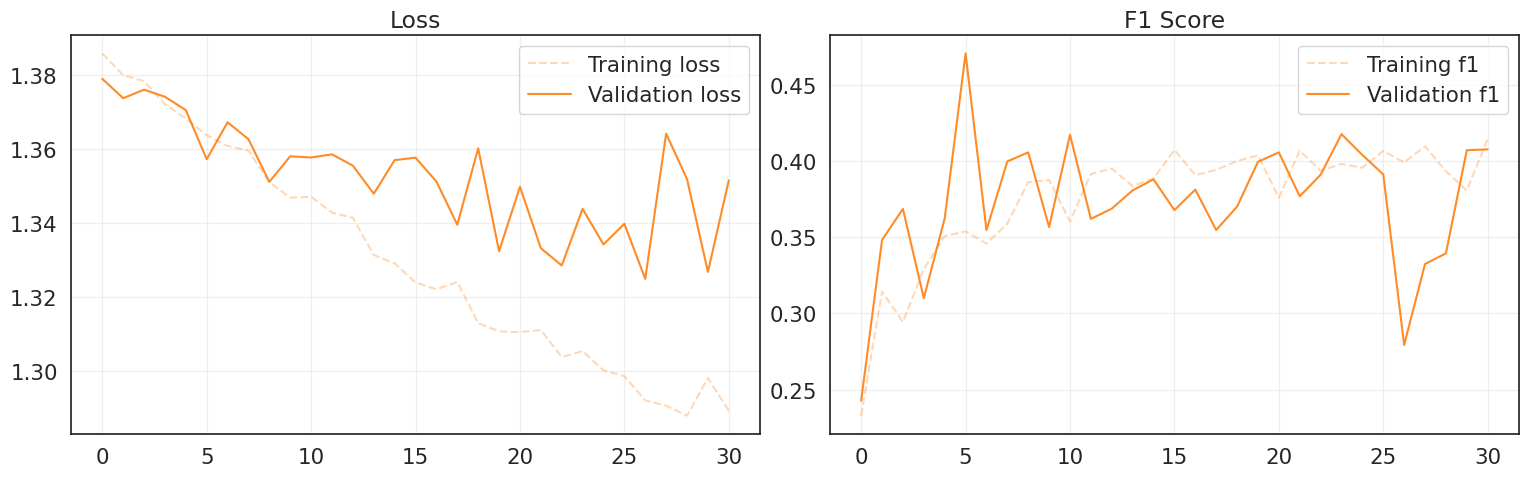

In [26]:
# @title Plot Hitory
# Create a figure with two side-by-side subplots (two columns)
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(tl_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(tl_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation accuracy on the second axis
ax2.plot(tl_history['train_f1'], label='Training f1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(tl_history['val_f1'], label='Validation f1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

## 🛠️ **Fine-Tuning**

In [ ]:
# Load the transfer learning model
ft_model = ResNet50TransferLearning(num_classes, DROPOUT_RATE, freeze_backbone=False).to(device)
ft_model.load_state_dict(torch.load("models/transfer_learning_model.pt"))

# First, freeze everything in the backbone
for param in ft_model.backbone.parameters():
    param.requires_grad = False

# Identify ResNet blocks to unfreeze. Here we unfreeze the last block (layer4).

trainable_blocks = [
    ft_model.backbone.layer4, # The last block (high-level features)
    #ft_model.backbone.layer3
]

# Unfreeze these blocks
for block in trainable_blocks:
    for param in block.parameters():
        param.requires_grad = True

# Count parameters
total_params = sum(p.numel() for p in ft_model.parameters())
trainable_params = sum(p.numel() for p in ft_model.parameters() if p.requires_grad)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

Total parameters: 24,559,172
Trainable parameters: 14,964,736
Frozen parameters: 9,594,436


In [ ]:
# Training Dataset
# Generate 10 random crops per image per epoch
train_dataset = GrumpyDoctogresDataset(
    samples=train_df['sample_index'].tolist(),
    labels=train_df['label_idx'].tolist(),
    data_dir=TRAIN_DIR,
    transform=train_transform,
    crops_per_image=CROPS_PER_IMAGE
)

# Validation Dataset
# Keep validation deterministic/single crop (crops_per_image=1 by default)
val_dataset = GrumpyDoctogresDataset(
    samples=val_df['sample_index'].tolist(),
    labels=val_df['label_idx'].tolist(),
    data_dir=TRAIN_DIR,
    transform=val_transform
)

# Test (Inference) Dataset
test_dataset = GrumpyDoctogresDataset(
    samples=test_files,
    labels=None,
    data_dir=TEST_DIR,
    transform=val_transform
)

# Data Loaders
train_loader = make_loader(train_dataset, BATCH_SIZE, shuffle=True, drop_last=False)
val_loader = make_loader(val_dataset, BATCH_SIZE, shuffle=False, drop_last=False)
test_loader = make_loader(test_dataset, BATCH_SIZE, shuffle=False, drop_last=False)

print(f"Original Training Samples: {len(train_df)}")
print(f"Augmented Training Samples: {len(train_dataset)}")
print("\nDataLoaders created successfully.")

Original Training Samples: 464
Augmented Training Samples: 2320

DataLoaders created successfully.


In [42]:
# OSS: fine-tuning needs a lower learning rate
experiment_name = "fine_tuning"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)

FT_LEARNING_RATE = 7e-6
optimizer = torch.optim.Adam(
    ft_model.parameters(),
    lr=FT_LEARNING_RATE,
    weight_decay=9e-3
)
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

In [43]:
%%time
# Fine-tune the model
ft_model, ft_history = fit(
    model=ft_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=1,
    experiment_name="fine_tuning",
    patience=PATIENCE
)

Training 200 epochs...
Epoch   1/200 | Train: Loss=1.3587, F1 Score=0.3641 | Val: Loss=1.3591, F1 Score=0.3788
Epoch   2/200 | Train: Loss=1.3559, F1 Score=0.3743 | Val: Loss=1.3651, F1 Score=0.3450
Epoch   3/200 | Train: Loss=1.3510, F1 Score=0.3691 | Val: Loss=1.3550, F1 Score=0.3515
Epoch   4/200 | Train: Loss=1.3427, F1 Score=0.3799 | Val: Loss=1.3567, F1 Score=0.3284
Epoch   5/200 | Train: Loss=1.3400, F1 Score=0.3839 | Val: Loss=1.3531, F1 Score=0.3422
Epoch   6/200 | Train: Loss=1.3187, F1 Score=0.4100 | Val: Loss=1.3417, F1 Score=0.3473
Epoch   7/200 | Train: Loss=1.3100, F1 Score=0.3977 | Val: Loss=1.3183, F1 Score=0.3585
Epoch   8/200 | Train: Loss=1.2958, F1 Score=0.3867 | Val: Loss=1.3399, F1 Score=0.3201
Epoch   9/200 | Train: Loss=1.2808, F1 Score=0.3885 | Val: Loss=1.3321, F1 Score=0.3115
Epoch  10/200 | Train: Loss=1.2690, F1 Score=0.3988 | Val: Loss=1.3378, F1 Score=0.3399
Epoch  11/200 | Train: Loss=1.2630, F1 Score=0.3892 | Val: Loss=1.2878, F1 Score=0.3327
Epoch  12

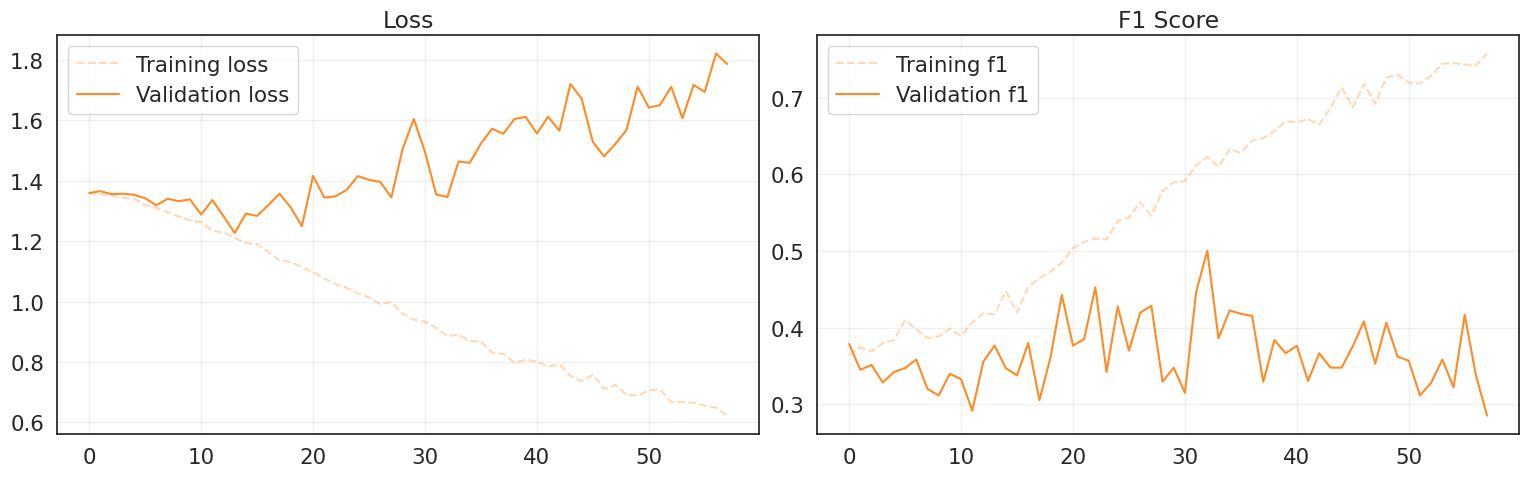

In [44]:
# @title Plot Hitory
# Create a figure with two side-by-side subplots (two columns)
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(ft_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(ft_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation accuracy on the second axis
ax2.plot(ft_history['train_f1'], label='Training f1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(ft_history['val_f1'], label='Validation f1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

In [ ]:
label_map = {'Luminal A': 0, 'Luminal B': 1, 'HER2(+)': 2, 'Triple negative': 3}
idx_to_label = {v: k for k, v in label_map.items()}

model_for_inference = ft_model if 'ft_model' in locals() else tl_model
model_for_inference.eval()

# Dictionary to store aggregated probabilities
file_probabilities = {}

# Multi-View Inference Loop (TTA)
# We take N "glances" at each slide
N_VIEWS = 50

print(f"Starting Multi-View Inference ({N_VIEWS} crops per image)...")

with torch.no_grad():
    # Loop N times over the entire dataset
    for round_idx in range(N_VIEWS):
        print(f"  - Round {round_idx + 1}/{N_VIEWS}...")

        for images, img_names in test_loader:
            images = images.to(device)

            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model_for_inference(images)
                # Convert logits to probabilities (Softmax) so we can sum them safely
                probs = torch.softmax(logits, dim=1).cpu().numpy()

            # Aggregate probabilities
            for name, p in zip(img_names, probs):
                if name not in file_probabilities:
                    file_probabilities[name] = p
                else:
                    file_probabilities[name] += p

# Final Decision (Soft Voting)
all_filenames = []
all_preds = []

print("Aggregating votes...")

for name, total_probs in file_probabilities.items():
    # We find the class with the highest ACCUMULATED probability
    pred_idx = total_probs.argmax()

    all_filenames.append(name)
    all_preds.append(idx_to_label[pred_idx])

# Create Submission
submission_df = pd.DataFrame({
    'sample_index': all_filenames,
    'label': all_preds
})

# Save
submission_df.to_csv("submission.csv", index=False)
print("File 'submission.csv' created successfully with 50-View Voting!")
print(submission_df.head())

Starting Multi-View Inference (50 crops per image)...
  - Round 1/50...
  - Round 2/50...
  - Round 3/50...
  - Round 4/50...
  - Round 5/50...
  - Round 6/50...
  - Round 7/50...
  - Round 8/50...
  - Round 9/50...
  - Round 10/50...
  - Round 11/50...
  - Round 12/50...
  - Round 13/50...
  - Round 14/50...
  - Round 15/50...
  - Round 16/50...
  - Round 17/50...
  - Round 18/50...
  - Round 19/50...
  - Round 20/50...
  - Round 21/50...
  - Round 22/50...
  - Round 23/50...
  - Round 24/50...
  - Round 25/50...
  - Round 26/50...
  - Round 27/50...
  - Round 28/50...
  - Round 29/50...
  - Round 30/50...
  - Round 31/50...
  - Round 32/50...
  - Round 33/50...
  - Round 34/50...
  - Round 35/50...
  - Round 36/50...
  - Round 37/50...
  - Round 38/50...
  - Round 39/50...
  - Round 40/50...
  - Round 41/50...
  - Round 42/50...
  - Round 43/50...
  - Round 44/50...
  - Round 45/50...
  - Round 46/50...
  - Round 47/50...
  - Round 48/50...
  - Round 49/50...
  - Round 50/50...
Aggre

Hunting for traitors in 117 validation samples...


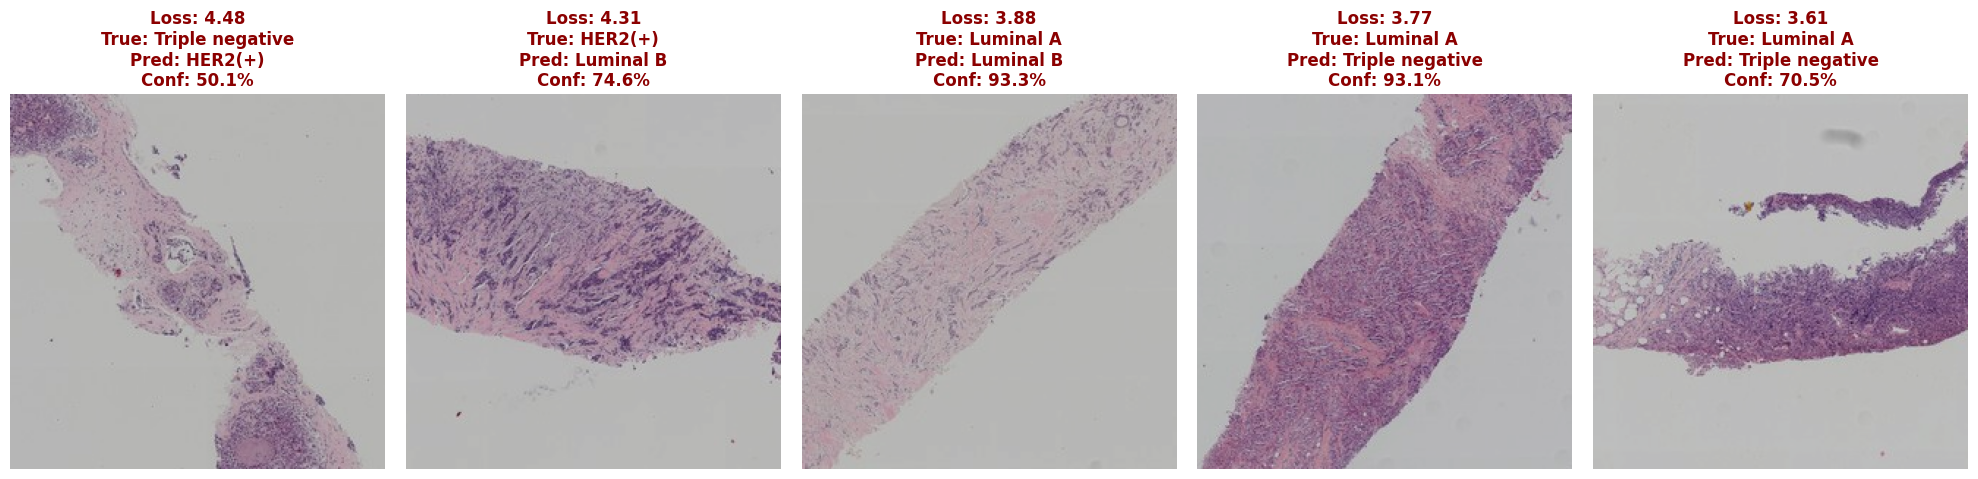

In [ ]:
def find_traitors(model, val_loader, criterion, device, idx_to_label, k=5):
    """
    Identifies and plots the top k samples with the highest loss (the 'traitors').
    """
    model.eval()
    losses = []
    
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    print(f"Hunting for traitors in {len(val_loader.dataset)} validation samples...")

    with torch.no_grad():
        for batch_idx, (inputs, targets) in enumerate(val_loader):
            inputs, targets = inputs.to(device), targets.to(device)
            
            logits = model(inputs)

            batch_loss = nn.CrossEntropyLoss(reduction='none')(logits, targets)

            probs = torch.softmax(logits, dim=1)
            predictions = logits.argmax(dim=1)

            for i in range(inputs.size(0)):
                losses.append({
                    'loss': batch_loss[i].item(),
                    'img_tensor': inputs[i].cpu(),
                    'true_idx': targets[i].item(),
                    'pred_idx': predictions[i].item(),
                    'conf': probs[i][predictions[i]].item()
                })

    losses.sort(key=lambda x: x['loss'], reverse=True)

    top_k = losses[:k]

    fig, axes = plt.subplots(1, k, figsize=(4 * k, 5))
    if k == 1: axes = [axes]

    for i, item in enumerate(top_k):
        ax = axes[i]

        img = item['img_tensor'].permute(1, 2, 0).numpy()

        img = std * img + mean
        img = np.clip(img, 0, 1) 

        true_name = idx_to_label[item['true_idx']]
        pred_name = idx_to_label[item['pred_idx']]

        ax.imshow(img)
        ax.axis('off')

        title = (f"Loss: {item['loss']:.2f}\n"
                 f"True: {true_name}\n"
                 f"Pred: {pred_name}\n"
                 f"Conf: {item['conf']:.1%}")
        ax.set_title(title, color='darkred', fontsize=12, fontweight='bold')

    plt.tight_layout()
    plt.show()

label_map = {'Luminal A': 0, 'Luminal B': 1, 'HER2(+)': 2, 'Triple negative': 3}
idx_to_label = {v: k for k, v in label_map.items()}

find_traitors(ft_model, val_loader, criterion, device, idx_to_label, k=5)